# Calculating Sheer and Veer from MetMasts
## Importing Libraries

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Reading In Dataset

In [11]:
# read in metmast dataset
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')

In [22]:
metmasts.head()

,utc,mm_wind_speed_1,mm_wind_speed_2,mm_wind_speed_3,mm_wind_speed_hh,mm_wind_direction_1,mm_wind_direction_2,mm_wind_direction_3,mm_wind_direction_hh,mm_pressure_bar_1,mm_pressure_bar_2,mm_rel_humidity_1,mm_rel_humidity_2,mm_temp_amb
0,2026-01-01 08:00:00,NaN,6.788382,5.399412,0.700615,71.916912,54.936030,67.719853,47.655736,NaN,875.645740,11.372340,4.810286,NaN
1,2026-01-01 08:10:00,NaN,6.259118,5.094412,0.697460,67.399852,51.146323,64.681471,43.452206,NaN,875.537235,11.323674,4.573111,NaN
2,2026-01-01 08:20:00,NaN,6.533529,5.542794,0.703226,72.914559,57.126323,70.034118,51.133089,NaN,875.370256,11.276522,4.534419,NaN
3,2026-01-01 08:30:00,NaN,6.125970,5.133824,0.711940,86.105735,65.834329,84.872500,58.976618,NaN,875.402339,11.249778,4.145185,NaN
4,2026-01-01 08:40:00,NaN,5.931143,5.168986,0.691642,90.357286,68.262572,87.822753,61.110143,NaN,875.489709,11.124737,4.001458,NaN


## Defining Shear

In [23]:
# defining the heights
speed_heights = {'mm_wind_speed_2': 50.44, 'mm_wind_speed_3': 87.63}
direction_heights = {'mm_wind_direction_1': 49.89, 'mm_wind_direction_3': 82.52}

# defining a minimum wind speed
min_wind_speed = 3.0

In [24]:
def wrap_diff(a, b):
    """Signed angular difference a - b in degrees, wrapped to [-180, 180)."""
    return (a - b + 180) % 360 - 180

In [25]:
def profile_slope(y, x):
    """Row-wise least-squares slope of y (n, k) against x (k,)."""
    xc = x - x.mean()
    yc = y - y.mean(axis = 1, keepdims = True)
    return (yc * xc).sum(axis = 1) / (xc ** 2).sum()

In [26]:
def shear_fit(df, heights):
    """Power-law shear exponent: slope of ln(speed) against ln(height)."""
    cols = sorted(heights, key = heights.get)
    x = np.log(np.array([heights[c] for c in cols], dtype = float))
    y = np.log(df[cols].to_numpy())
    return pd.Series(profile_slope(y, x), index = df.index)

In [27]:
def veer_fit(df, heights):
    """Veer in deg/100 m: slope of unwrapped direction against height."""
    cols = sorted(heights, key = heights.get)
    x = np.array([heights[c] for c in cols], dtype = float)
    theta = df[cols].to_numpy()
    ref = theta[:, [0]]                    
    y = ref + wrap_diff(theta, ref)          
    return pd.Series(profile_slope(y, x) * 100, index = df.index)

In [28]:
def valid_mask(df, heights_speed, heights_direction, min_ws = min_wind_speed):
    """All speeds above the threshold and all directions present."""
    ws = df[list(heights_speed)]
    wd = df[list(heights_direction)]
    return (ws > min_ws).all(axis = 1) & wd.notna().all(axis = 1)

In [29]:
def wind_analysis(df, heights_speed = speed_heights, heights_direction = direction_heights, min_ws = min_wind_speed):
    data = df[valid_mask(df, heights_speed, heights_direction, min_ws)].copy()
    data['shear'] = shear_fit(data, heights_speed)
    data['veer'] = veer_fit(data, heights_direction)
    return data

In [30]:
# running the function
metmasts_shear_veer = wind_analysis(metmasts)

In [31]:
# analyzing the shear column
metmasts_shear_veer['shear'].describe()

count    35007.000000
mean         0.040370
std          0.595255
min         -2.857385
25%         -0.311955
50%         -0.097702
75%          0.327655
max          3.029001
Name: shear, dtype: float64

In [32]:
# analyzing the veer column
metmasts_shear_veer['veer'].describe()

count    35007.000000
mean         6.861146
std         11.578789
min       -271.769110
25%          0.541795
50%          5.568350
75%         12.208702
max        110.263022
Name: veer, dtype: float64

In [33]:
# looking into how much of the data is missing from the original dataset
1 - (metmasts_shear_veer.shape[0] / metmasts.shape[0])

0.10937261486795913

In [34]:
# looking at the very large values of veer
metmasts_shear_veer.sort_values('veer').head(10)

,utc,mm_wind_speed_1,mm_wind_speed_2,mm_wind_speed_3,mm_wind_speed_hh,mm_wind_direction_1,mm_wind_direction_2,mm_wind_direction_3,mm_wind_direction_hh,mm_pressure_bar_1,mm_pressure_bar_2,mm_rel_humidity_1,mm_rel_humidity_2,mm_temp_amb,shear,veer
6920,2026-02-18 09:20:00,NaN,9.637660,7.139318,13.450145,285.638260,218.745652,196.960000,280.900144,NaN,864.077226,6.000597,12.200308,NaN,-0.543255,-271.769110
6919,2026-02-18 09:10:00,NaN,18.416316,13.037234,14.861159,286.110735,257.612317,199.654493,278.402208,639.234985,863.894735,5.894478,12.443846,NaN,-0.625391,-264.959368
5512,2026-02-08 14:40:00,NaN,3.060000,3.502576,2.268276,248.129698,86.781364,196.734626,153.736269,NaN,883.706474,-10.782400,79.518096,NaN,0.244567,-157.508648
10801,2026-03-17 08:10:00,NaN,3.822258,5.258064,4.128571,234.475692,158.574688,183.719999,117.613538,NaN,878.936734,-9.380417,77.417660,29.673333,0.577402,-155.549166
3062,2026-01-22 14:20:00,NaN,6.112273,6.025000,5.010820,88.635373,132.423582,40.603582,185.926060,NaN,874.604044,-10.769231,77.367593,15.912500,-0.026037,-147.201321
10656,2026-03-16 08:00:00,NaN,4.400152,3.355846,1.916393,124.714628,167.842274,83.225821,72.103582,NaN,879.191106,-9.679444,77.718379,28.490000,-0.490523,-127.149268
9325,2026-03-07 02:10:00,NaN,3.281270,3.805000,2.560690,236.083484,34.763846,198.881212,267.182122,NaN,876.652591,-12.330000,77.510222,NaN,0.268106,-114.012477
3083,2026-01-22 17:50:00,NaN,7.182206,6.915909,5.919701,127.605588,111.722389,90.643088,159.570735,NaN,875.620006,-10.441143,77.322641,17.536000,-0.068404,-113.277661
7151,2026-02-19 23:50:00,NaN,13.573710,11.708182,14.805916,284.810984,263.646620,249.181326,276.683238,NaN,863.622651,8.468939,14.956667,NaN,-0.267674,-109.192946
6918,2026-02-18 09:00:00,NaN,7.564630,11.876229,18.134627,271.973134,199.253581,238.632273,264.520895,NaN,863.220996,4.732424,13.046515,NaN,0.816628,-102.178552


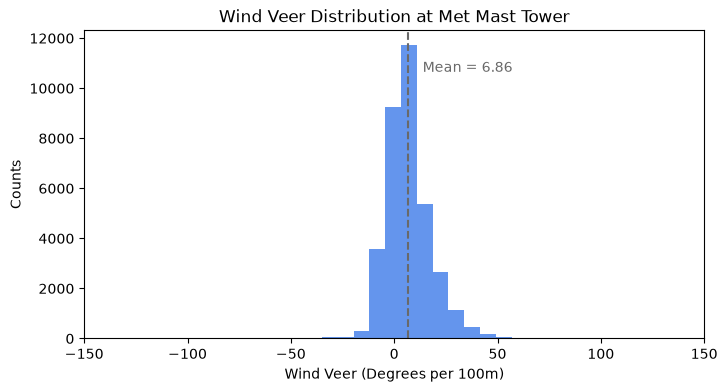

In [35]:
# defining the mean veer value
veer_mean = metmasts_shear_veer['veer'].mean()

# plotting the veer distribution
metmasts_shear_veer['veer'].plot.hist(bins = 50, color = 'cornflowerblue', figsize = (8, 4))
plt.axvline(veer_mean, color = 'dimgray', linestyle = '--')
plt.text(veer_mean + 5, plt.ylim()[1] * 0.9, f' Mean = {veer_mean:.2f}', color = 'dimgray', va = 'top')
plt.xlim(-150, 150)
plt.xlabel('Wind Veer (Degrees per 100m)')
plt.ylabel('Counts')
plt.title('Wind Veer Distribution at Met Mast Tower')
plt.show()

In [73]:
def veer_table(df, rename_map = None, n = None, decimals = 3):
    cols = ["mm_wind_direction_1", "mm_wind_direction_2", "mm_wind_direction_3", "mm_wind_direction_hh", "veer"]
    if rename_map is None:
        rename_map = {
            "mm_wind_direction_1": "Wind Direction Height 1 (degrees)",
            "mm_wind_direction_2": "Wind Direction Height 2 (degrees)",
            "mm_wind_direction_3": "Wind Direction Height 3 (degrees)",
            "mm_wind_direction_hh": "Wind Direction Height 4 (degrees)",
            "veer": "Veer (deg/100m)",
        }

    table = (
        df[cols]
        .sort_values("veer", ascending = True)
        .rename(columns = rename_map)
        .round(decimals)
        .reset_index(drop=True)
    )
    if n is not None:
        table = table.head(n)

    return table

In [75]:
veer_table(metmasts_shear_veer, n = 8)

,Wind Direction Height 1 (degrees),Wind Direction Height 2 (degrees),Wind Direction Height 3 (degrees),Wind Direction Height 4 (degrees),Veer (deg/100m)
0,45.262,180.557,29.520,243.970,-317.457
1,325.098,108.642,325.232,213.208,-239.540
2,299.710,104.754,273.659,220.673,-214.102
3,295.302,73.789,286.313,203.231,-211.846
4,285.197,101.323,270.583,210.807,-206.954
5,295.863,113.897,294.457,219.198,-204.717
6,301.831,112.257,287.998,229.061,-201.284
7,319.933,66.281,298.720,230.959,-197.242


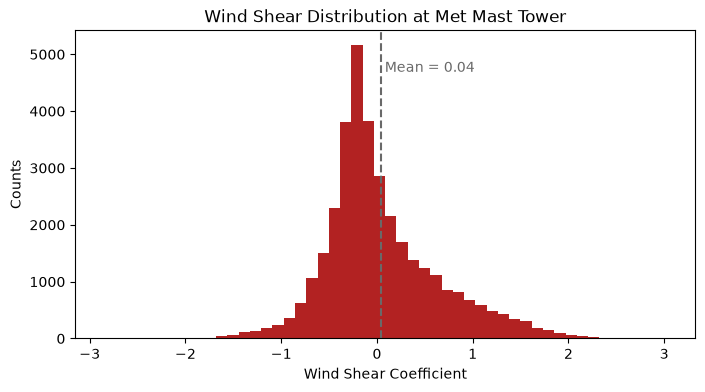

In [36]:
# defining the mean shear value
shear_mean = metmasts_shear_veer['shear'].mean()

# plotting the shear distribution
metmasts_shear_veer['shear'].plot.hist(bins = 50, color = 'firebrick', figsize = (8, 4))
plt.axvline(shear_mean, color = 'dimgray', linestyle = '--')
plt.text(shear_mean, plt.ylim()[1] * 0.9, f' Mean = {shear_mean:.2f}', color = 'dimgray', va = 'top')
plt.xlabel('Wind Shear Coefficient')
plt.ylabel('Counts')
plt.title('Wind Shear Distribution at Met Mast Tower')
plt.show()